In [139]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression, Lasso, Ridge

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [140]:
df = pd.read_csv('../datasets/Boston.csv')
df.head(3)

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,House_Price
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7


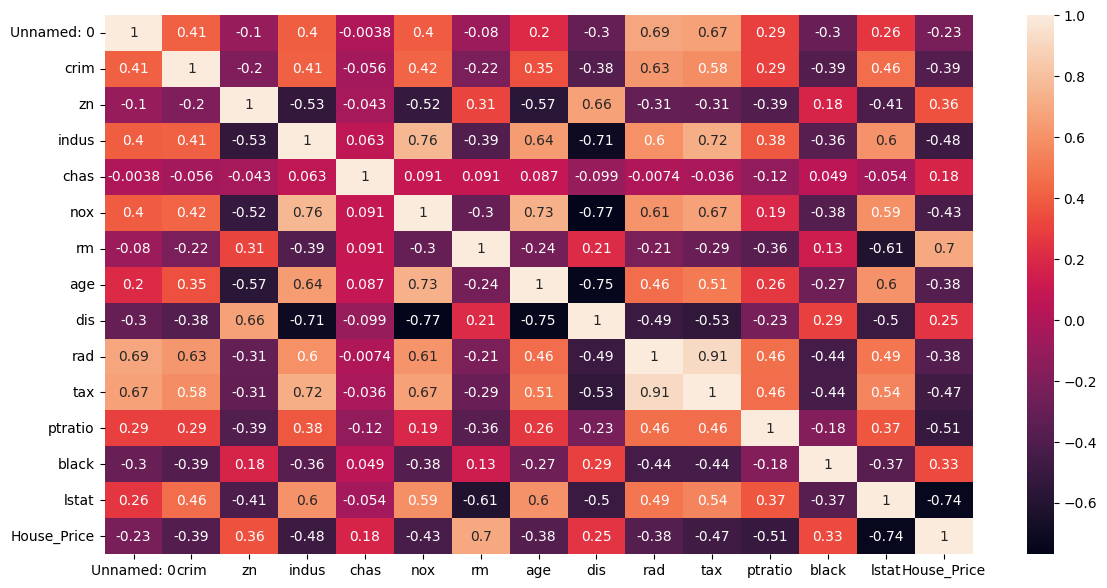

In [141]:
plt.figure(figsize=(14,7))
sns.heatmap(df.corr(), annot=True)
plt.show()

The above dataset is not corelated, we should not apply regression on such datasets
But here for purpose of demo implementing and learning we ae going with it

In [142]:
x = df.iloc[:, :-1]
y = df['House_Price']

x.ndim, y.ndim

(2, 1)

In [143]:
ss = StandardScaler()

ss.fit(x)

StandardScaler()

In [144]:
ss.transform(x)

array([[-1.72863116, -0.41978194,  0.28482986, ..., -1.45900038,
         0.44105193, -1.0755623 ],
       [-1.72178509, -0.41733926, -0.48772236, ..., -0.30309415,
         0.44105193, -0.49243937],
       [-1.71493903, -0.41734159, -0.48772236, ..., -0.30309415,
         0.39642699, -1.2087274 ],
       ...,
       [ 1.71493903, -0.41344658, -0.48772236, ...,  1.17646583,
         0.44105193, -0.98304761],
       [ 1.72178509, -0.40776407, -0.48772236, ...,  1.17646583,
         0.4032249 , -0.86530163],
       [ 1.72863116, -0.41500016, -0.48772236, ...,  1.17646583,
         0.44105193, -0.66905833]])

In [145]:
x = pd.DataFrame(ss.transform(x))

In [146]:
df.head(3)

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,House_Price
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7


In [147]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [148]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

---

## Linear Regression

In [149]:
lr = LinearRegression()

lr.fit(x_train, y_train)

LinearRegression()

In [150]:
lr.score(x_test, y_test)

0.6659408703343037

In [151]:
lr.coef_

array([-0.50757753, -0.97370848,  0.75272672,  0.29848454,  0.69937114,
       -1.96087123,  3.14926774, -0.30701258, -3.10512624,  2.54580207,
       -1.67057587, -1.97149334,  1.13278249, -3.65448289])

In [152]:
print(mean_squared_error(y_test, lr.predict(x_test)))
print(mean_absolute_error(y_test, lr.predict(x_test)))
print(np.sqrt(mean_squared_error(y_test, lr.predict(x_test))))

24.497819777630383
3.2007547573408224
4.9495272276885585


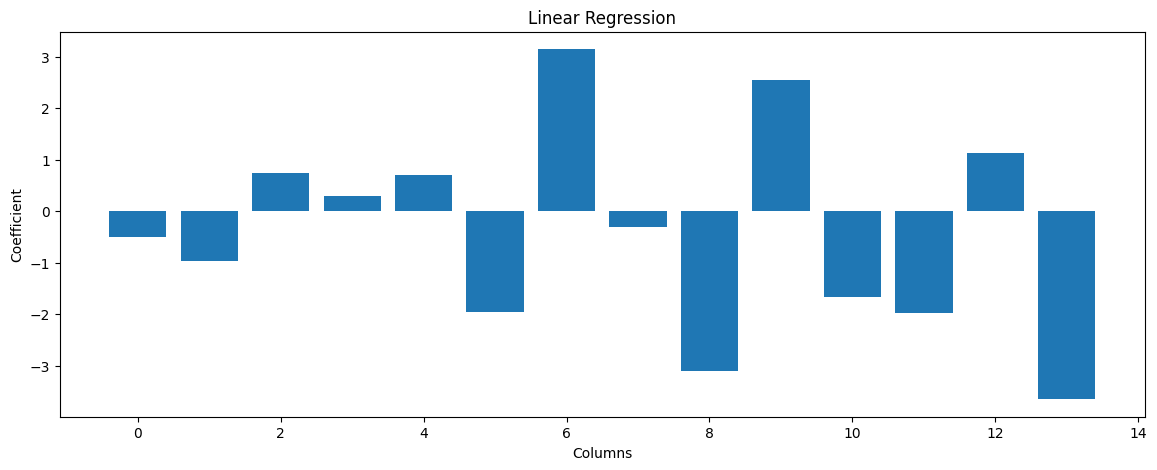

In [153]:
plt.figure(figsize=(14,5))
plt.bar(x.columns, lr.coef_)
plt.title("Linear Regression")
plt.xlabel("Columns")
plt.ylabel("Coefficient")
plt.show()

---

## Lasso

In [154]:
l1 = Lasso(alpha=0.5) # alpha is penalty corner # default 1
l1.fit(x_train, y_train)

l1.score(x_test, y_test)

0.6275318666956766

In [155]:
print(mean_squared_error(y_test, l1.predict(x_test)))
print(mean_absolute_error(y_test, l1.predict(x_test)))
print(np.sqrt(mean_squared_error(y_test, l1.predict(x_test))))

27.314497321869517
3.3059052053438056
5.226327326322904


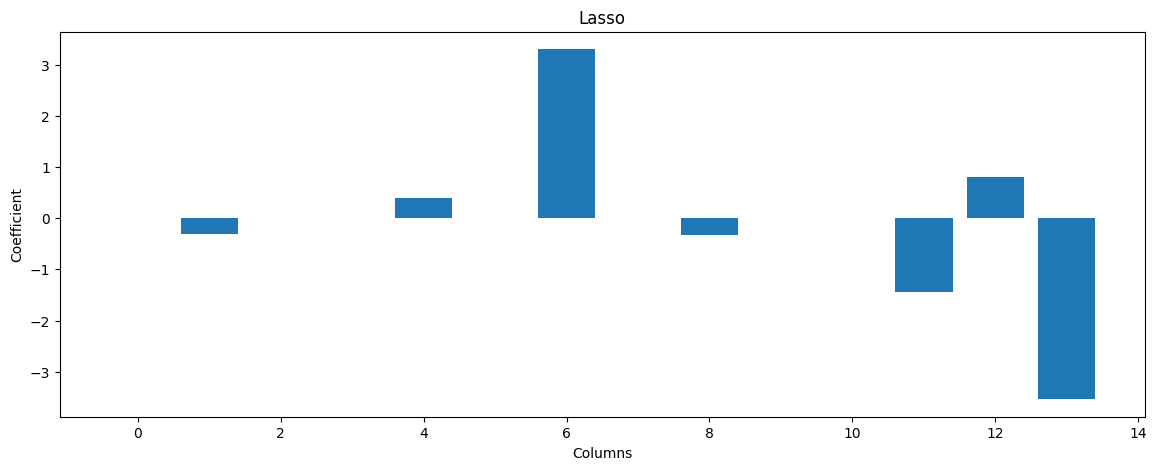

In [156]:
plt.figure(figsize=(14,5))
plt.bar(x.columns, l1.coef_)
plt.title("Lasso")
plt.xlabel("Columns")
plt.ylabel("Coefficient")
plt.show()

The difference we can see that the data is reduced here as **Lasso** does feature selection.

---

## Ridge

In [157]:
l2 = Ridge(alpha=10)
l2.fit(x_train, y_train)

l2.score(x_test, y_test)

0.66438807907533

In [158]:
print(mean_squared_error(y_test, l2.predict(x_test)))
print(mean_absolute_error(y_test, l2.predict(x_test)))
print(np.sqrt(mean_squared_error(y_test, l2.predict(x_test))))

24.611691835109205
3.1750197340490875
4.961017217779959


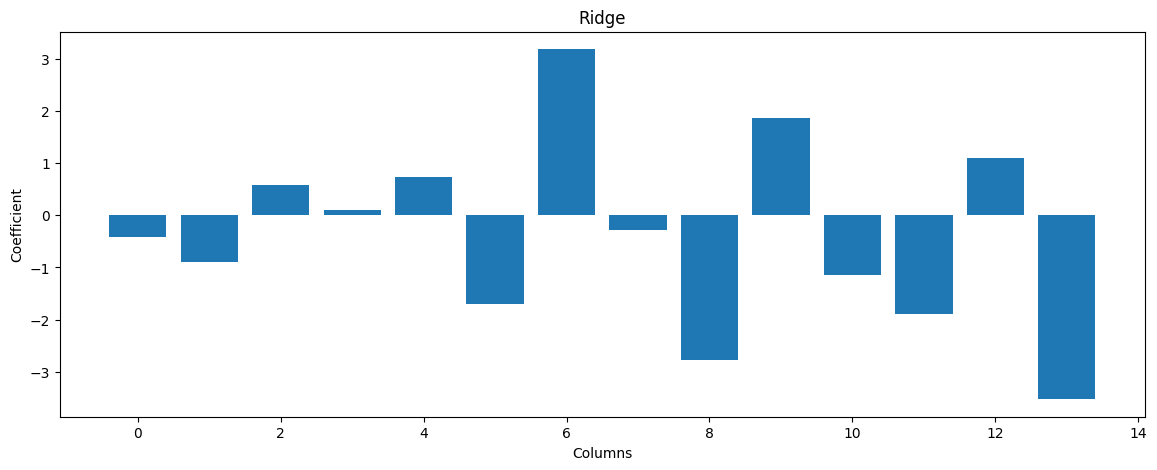

In [159]:
plt.figure(figsize=(14,5))
plt.bar(x.columns, l2.coef_)
plt.title("Ridge")
plt.xlabel("Columns")
plt.ylabel("Coefficient")
plt.show()

---

In [160]:
df = pd.DataFrame({
    "col_names":x.columns,
    "LinearRegression": lr.coef_,
    "Lasso": l1.coef_,
    "Ridge": l2.coef_,
})

df

,col_names,LinearRegression,Lasso,Ridge
0,0,-0.507578,-0.000000,-0.406150
1,1,-0.973708,-0.317134,-0.892614
2,2,0.752727,0.000000,0.591169
3,3,0.298485,-0.000000,0.096365
4,4,0.699371,0.402420,0.730310
5,5,-1.960871,-0.000000,-1.706599
6,6,3.149268,3.300463,3.187543
7,7,-0.307013,-0.000000,-0.282658
8,8,-3.105126,-0.338297,-2.769952
9,9,2.545802,-0.000000,1.863926


---